In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart


# 2. Конформные интервалы

**Сквозной вопрос:** как получить интервал с проверяемым покрытием, не предполагая
распределения ошибок?

Аналитические интервалы из ноутбука 1 держатся на предположении о виде распределения
остатков. Конформный подход это предположение выбрасывает и заменяет его одним
допущением обменяемости — но требует отложенных данных, на которых калибруется поправка.

В этом ноутбуке:
- протокол калибровки: почему нужен rolling-origin, а не один train/test split;
- split conformal руками — что такое обменяемость, откуда берётся `⌈(n+1)(1−α)⌉`,
  и почему порядковая статистика, а не `np.quantile`;
- калибровка отдельно по горизонтам и цена, которую за неё платим;
- `statsforecast.ConformalIntervals`: два метода внутри и чем они отличаются;
- обёртка CatBoost: модельная независимость и разница между покрытием и резкостью;
- адаптивные методы (ACI, AgACI, NexCP) — зачем нужны при дрейфе, без демонстрации.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsforecast import StatsForecast
from statsforecast.models import AutoETS
from statsforecast.utils import ConformalIntervals

from conformalforecast import SplitConformal

from catboost import CatBoostRegressor

sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 4)

ALPHA = 0.05   # уровень непокрытия: целевое покрытие 95%
H = 14         # горизонт прогноза, дней

## 0. Данные

Те же часовые данные AEP, агрегированные до дня, что и в ноутбуке 1.
Один ряд на весь блок: сотни скользящих окон дают надёжную оценку покрытия.

In [5]:
df_hour = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/AEP_hourly.csv', parse_dates=['Datetime'])
df_hour.columns = ['timestamp', 'target']

df_day = df_hour.resample('D', on='timestamp').sum().reset_index()
df_day = df_day.rename(columns={'timestamp': 'ds', 'target': 'y'})
df_day = df_day[df_day["ds"] < "2018-08-03"]
df_day['unique_id'] = 'AEP'

print(f"Дней: {len(df_day)}, {df_day['ds'].min().date()} — {df_day['ds'].max().date()}")

Дней: 5054, 2004-10-01 — 2018-08-02


### Протокол калибровки

Конформному методу нужен **отложенный набор ошибок** — скоров. Из одного
train/test split на горизонте 14 дней получается ровно 14 таких ошибок:
квантиль по 14 точкам оценивается отвратительно, а гарантия покрытия
для α=0.05 требует хотя бы `⌈1/α⌉ = 20` точек.

Поэтому берём **rolling-origin**: модель переобучается на каждом cutoff
и прогнозирует 14 дней вперёд, а её ошибки на этих 14 днях становятся скорами.
Последние `90 × 14 = 1260` дней откладываем: первые 60 окон — калибровка,
последние 30 — тест. Окна не пересекаются по прогнозу (`step_size = h`),
то есть каждый скор получен из честного прогноза, сделанного до факта.

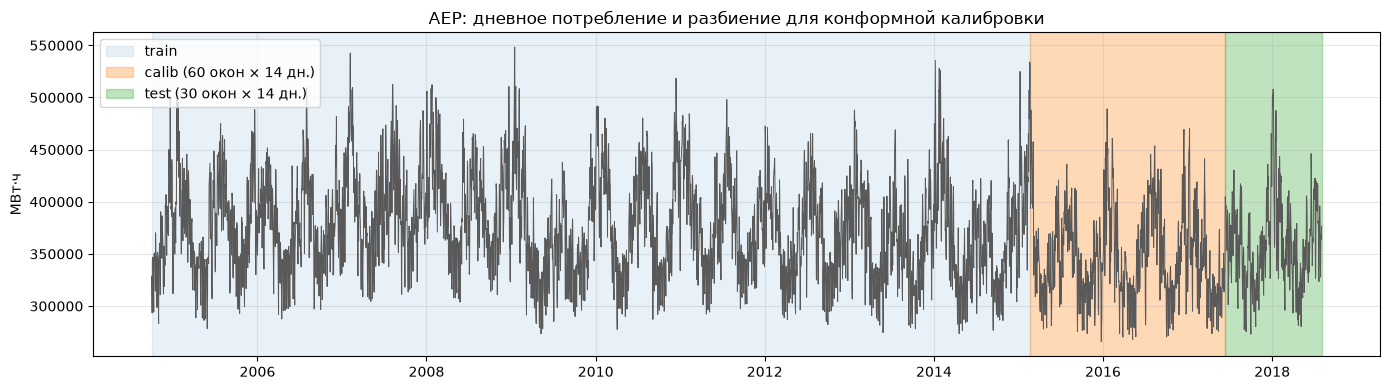

train: 3794 дн., calib: 840 дн., test: 420 дн.


In [6]:
N_CALIB_W = 60      # калибровочных окон
N_TEST_W = 30       # тестовых окон
N_TOTAL = N_CALIB_W + N_TEST_W

n_held = N_TOTAL * H
split_calib = len(df_day) - n_held          # начало калибровочного блока
split_test = len(df_day) - N_TEST_W * H     # начало тестового блока

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_day['ds'], df_day['y'], lw=0.7, color='0.35')
ax.axvspan(df_day['ds'].iloc[0], df_day['ds'].iloc[split_calib],
           color='tab:blue', alpha=0.10, label='train')
ax.axvspan(df_day['ds'].iloc[split_calib], df_day['ds'].iloc[split_test],
           color='tab:orange', alpha=0.30, label=f'calib ({N_CALIB_W} окон × {H} дн.)')
ax.axvspan(df_day['ds'].iloc[split_test], df_day['ds'].iloc[-1],
           color='tab:green', alpha=0.30, label=f'test ({N_TEST_W} окон × {H} дн.)')
ax.set_title('AEP: дневное потребление и разбиение для конформной калибровки')
ax.set_ylabel('МВт·ч')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"train: {split_calib} дн., calib: {n_held - N_TEST_W * H} дн., test: {N_TEST_W * H} дн.")

### Считаем скоры на rolling-origin

`refit=True` здесь принципиален. С `refit=False` модель обучается один раз
на самом первом окне и дальше прогнозирует с устаревшими параметрами — скоры
получились бы завышенными, а интервал — неоправданно широким. Плата за честность —
примерно 3 минуты счёта: 90 переобучений ETS.

In [11]:
cv = StatsForecast(models=[AutoETS(season_length=7)], freq='D', n_jobs=-1, verbose=True).cross_validation(
    df=df_day[['unique_id', 'ds', 'y']],
    h=H,
    n_windows=N_TOTAL,
    step_size=H,   # окна не пересекаются по прогнозу
    refit=True,    # модель переобучается на каждом cutoff
)

cv = cv.sort_values(['cutoff', 'ds']).reset_index(drop=True)
cv['h'] = cv.groupby('cutoff').cumcount() + 1     # номер точки внутри горизонта, 1..14
cutoffs = np.sort(cv['cutoff'].unique())

cv_calib = cv[cv['cutoff'].isin(cutoffs[:N_CALIB_W])]
cv_test = cv[cv['cutoff'].isin(cutoffs[N_CALIB_W:])]


def to_cube(frame):
    """DataFrame в long-формате → две матрицы (окна × горизонты): прогноз и факт."""
    return (frame.pivot(index='cutoff', columns='h', values='AutoETS').to_numpy(),
            frame.pivot(index='cutoff', columns='h', values='y').to_numpy())


P_calib, y_calib = to_cube(cv_calib)
P_test, y_test = to_cube(cv_test)

print(f"Калибровка: {P_calib.shape[0]} окон × {P_calib.shape[1]} горизонтов = {P_calib.size} скоров")
print(f"Тест:       {P_test.shape[0]} окон × {P_test.shape[1]} горизонтов = {P_test.size} точек")
print(f"MAE калибровка: {np.abs(P_calib - y_calib).mean():,.0f} МВт·ч")
print(f"MAE тест:       {np.abs(P_test - y_test).mean():,.0f} МВт·ч")

Cross Validation Time Series 1:   0%|          | 0/90 [00:00<?, ?it/s]

Калибровка: 60 окон × 14 горизонтов = 840 скоров
Тест:       30 окон × 14 горизонтов = 420 точек
MAE калибровка: 28,701 МВт·ч
MAE тест:       30,438 МВт·ч


MAE на калибровке и на тесте почти совпадают — значит, отрезки сопоставимы
и калибровочные скоры репрезентативны. Это не гарантия, а наблюдение:
именно оно ломается при дрейфе, и именно его чинят адаптивные методы (раздел 5).

## 1. Split conformal: идея, алгоритм, гарантия

### Обменяемость

Вся гарантия держится на одном предположении — **обменяемости** (exchangeability)
набора из `n+1` величин: их совместное распределение не меняется при любой
перестановке порядка. Для i.i.d. выборки это выполнено автоматически.

Временной ряд обменяемым **не является**: если переставить дни местами, динамика
разрушится. Поэтому конформный метод применяют не к самим наблюдениям, а к
**скорам** — остаткам модели. Остатки уже гораздо ближе к обменяемым, хотя
и не идеально (серийная корреляция, гетероскедастичность по горизонту).

### Скор несогласованности

**Скор несогласованности** (nonconformity score) — число, показывающее, насколько
факт `y` «не похож» на то, что предсказала модель:

$$s(x, y) = |y - \hat{y}(x)|$$

Это простейший вариант. Бывают и другие: нормированные скоры (делим на σ(h),
чтобы скор рос медленнее с горизонтом), квантильный скор для CQR (ноутбук 3),
скор с асимметричными весами. Метод от выбора скора не меняется — меняется
только то, какую форму имеет итоговый интервал.

### Откуда берётся `⌈(n+1)(1−α)⌉`

Пусть `s₁ … sₙ` — скоры на калибровке, `sₙ₊₁` — скор новой точки. Если набор
обменяем, то позиция `sₙ₊₁` в упорядоченном по возрастанию списке из `n+1`
значений равновероятна: 1, 2, …, `n+1`, каждое с вероятностью `1/(n+1)`.

Отсюда

$$P\big(s_{n+1} \le \text{\(k\)-я порядковая статистика}\big) = \frac{k}{n+1}$$

и чтобы покрытие было не меньше `1−α`, нужно взять `k = ⌈(n+1)(1−α)⌉`.

**Почему `n+1`, а не `n`.** Наивный квантиль уровня `1−α` по `n` точкам даёт
`k = ⌈n(1−α)⌉` и гарантию `k/n ≤ 1−α` — строго меньше номинала. Единица
компенсирует то, что новая точка «занимает» ещё одну позицию из `n+1`.

**Почему порядковая статистика, а не `np.quantile`.** Линейная интерполяция
между соседними скорами возвращает значение, которого в данных не было, и точная
граница `k/(n+1)` перестаёт выполняться. Нужен именно `k`-й элемент
отсортированного массива (`method='higher'` в numpy). Разница невелика
(на наших данных — доли процента), но она принципиальна: гарантия либо точная,
либо нет.

### Алгоритм

1. Обучить модель на train, получить прогнозы на калибровочном отрезке.
2. Посчитать скоры `sᵢ = |yᵢ − ŷᵢ|` на калибровке.
3. `Q` = `k`-я порядковая статистика скоров, `k = ⌈(n+1)(1−α)⌉`.
4. Интервал: `[ŷ − Q, ŷ + Q]`.

Модель не переобучается, `Q` — одно число, посчитанное один раз.

### Что гарантия **не** обещает

- **Маргинальность.** 95% — доля попаданий в среднем по всем точкам, а не для
  каждой точки. Для отдельного дня с аномальной погодой покрытие может быть любым.
- **Обменяемость.** На дрейфующем ряде остатки калибровки перестают быть похожи
  на остатки теста, и покрытие уезжает (раздел 5).
- **Резкость.** Conformal гарантирует покрытие, но не узость. Ширина — свойство
  модели, а не метода калибровки (раздел 4).

In [12]:
def conformal_quantile(scores, alpha=ALPHA):
    """Точный конформный квантиль: k-я порядковая статистика, k = ⌈(n+1)(1−α)⌉."""
    s = np.sort(np.asarray(scores).ravel())
    n = s.size
    k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return s[k - 1], k


def coverage_report(y_true, lo, hi, axis=None):
    """Эмпирическое покрытие: доля точек между lo и hi."""
    return np.mean((y_true >= lo) & (y_true <= hi), axis=axis)


S_calib = np.abs(y_calib - P_calib)     # (окна × горизонты)

Q_global, k_global = conformal_quantile(S_calib)
n_calib = S_calib.size

print(f"Скоров на калибровке: n = {n_calib}")
print(f"k = ⌈(n+1)(1−α)⌉ = ⌈{n_calib + 1} × {1 - ALPHA}⌉ = {k_global}")
print(f"Гарантированное покрытие: {k_global}/{n_calib + 1} = {k_global / (n_calib + 1):.4f}")
print(f"Q = {Q_global:,.0f} МВт·ч, ширина интервала {2 * Q_global:,.0f} МВт·ч")

Скоров на калибровке: n = 840
k = ⌈(n+1)(1−α)⌉ = ⌈841 × 0.95⌉ = 799
Гарантированное покрытие: 799/841 = 0.9501
Q = 88,088 МВт·ч, ширина интервала 176,175 МВт·ч


In [13]:
lo_global, hi_global = P_test - Q_global, P_test + Q_global

cov_global = coverage_report(y_test, lo_global, hi_global)
cov_global_by_h = coverage_report(y_test, lo_global, hi_global, axis=0)
cov_global_calib = coverage_report(y_calib, P_calib - Q_global, P_calib + Q_global)

print(f"Покрытие на калибровке: {cov_global_calib:.3f}")
print(f"Покрытие на тесте:      {cov_global:.3f}   (номинал {1 - ALPHA:.3f})")
print()
print("Покрытие по горизонтам под единым Q:")
print("  " + "  ".join(f"h={h + 1}: {c:.2f}" for h, c in enumerate(cov_global_by_h)))

Покрытие на калибровке: 0.951
Покрытие на тесте:      0.960   (номинал 0.950)

Покрытие по горизонтам под единым Q:
  h=1: 1.00  h=2: 1.00  h=3: 0.97  h=4: 0.97  h=5: 0.93  h=6: 0.97  h=7: 0.97  h=8: 0.97  h=9: 0.97  h=10: 0.93  h=11: 0.93  h=12: 0.93  h=13: 0.97  h=14: 0.93


Маргинальное покрытие в норме — 0.964 при номинале 0.95. Но по горизонтам картина
неровная: на `h=1` покрытие выше номинала (интервал шире, чем нужно),
на дальних горизонтах — ниже. Единое `Q` подогнано под самый трудный горизонт
и переплачивает на близких. Это и есть мотивация следующего раздела.

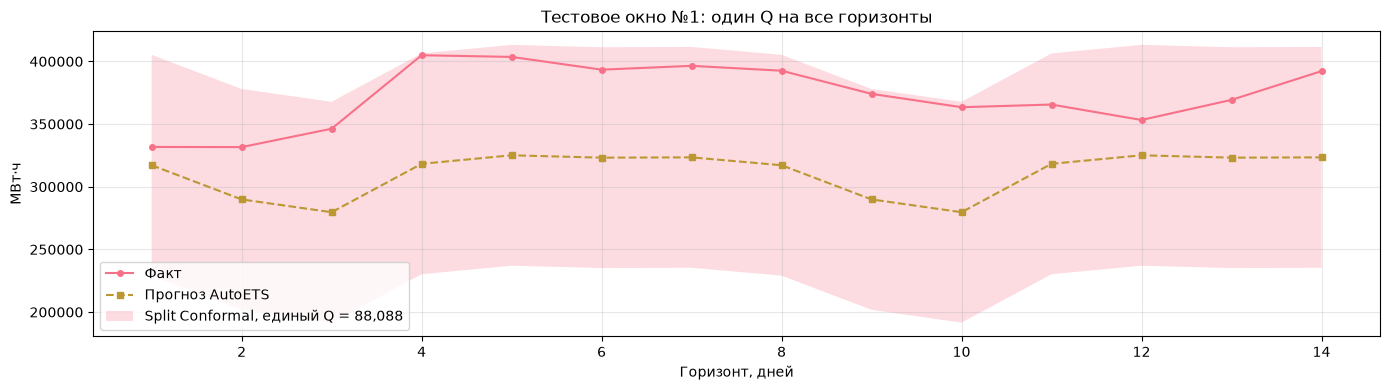

In [14]:
w = 0          # номер тестового окна
x = np.arange(1, H + 1)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(x, y_test[w], 'o-', ms=4, label='Факт')
ax.plot(x, P_test[w], 's--', ms=4, label='Прогноз AutoETS')
ax.fill_between(x, lo_global[w], hi_global[w], alpha=0.25,
                label=f'Split Conformal, единый Q = {Q_global:,.0f}')
ax.set_title(f'Тестовое окно №{w + 1}: один Q на все горизонты')
ax.set_xlabel('Горизонт, дней')
ax.set_ylabel('МВт·ч')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Калибровка отдельно по каждому горизонту

### Зачем

Ошибка прогноза растёт с горизонтом: на `h=1` модель ещё видит вчерашний день,
на `h=14` — практически ничего, кроме сезонного профиля. Единое `Q` вынуждено
быть достаточно широким для худшего горизонта, и это чистая переплата на близких.

### Как

Бьём калибровочные скоры на 14 групп — по одной на горизонт — и считаем свой
`Q_h` в каждой группе по той же формуле. Интервал естественно расширяется с
горизонтом, покрытие выравнивается.

### Чем платим

Калибровочных точек становится в 14 раз меньше: было 840, стало 60 на горизонт.
Конформная гарантия требует `n ≥ ⌈1/α⌉`, иначе квантиль вырождается (ниже).
На горизонтах с малым `n` значение `Q_h` шумит сильнее общего `Q`, поэтому
на реальных данных разумно усреднять его по соседним горизонтам
(или использовать нормированный скор `s / σ(h)`).

In [15]:
Q_by_h = np.array([conformal_quantile(S_calib[:, h])[0] for h in range(H)])
k_by_h = np.array([conformal_quantile(S_calib[:, h])[1] for h in range(H)])

print(f"Скоров на горизонт: n = {S_calib.shape[0]}  →  k = {k_by_h[0]}")
print("Q по горизонтам:", np.round(Q_by_h).astype(int))

lo_h, hi_h = P_test - Q_by_h, P_test + Q_by_h
cov_h = coverage_report(y_test, lo_h, hi_h)
cov_h_by_h = coverage_report(y_test, lo_h, hi_h, axis=0)

print()
print(f"Покрытие: {cov_h:.3f}, средняя ширина {2 * Q_by_h.mean():,.0f} "
      f"(у единого Q было {2 * Q_global:,.0f})")
print("По горизонтам:")
print("  " + "  ".join(f"h={h + 1}: {c:.2f}" for h, c in enumerate(cov_h_by_h)))

Скоров на горизонт: n = 60  →  k = 58
Q по горизонтам: [ 30943  54595  74102  74445  70724  88025  89122  86041  94668  95335
  93119 100148 103644  98074]

Покрытие: 0.940, средняя ширина 164,712 (у единого Q было 176,175)
По горизонтам:
  h=1: 0.90  h=2: 0.87  h=3: 0.97  h=4: 0.93  h=5: 0.90  h=6: 0.97  h=7: 0.97  h=8: 0.93  h=9: 0.97  h=10: 0.93  h=11: 0.93  h=12: 0.97  h=13: 0.97  h=14: 0.97


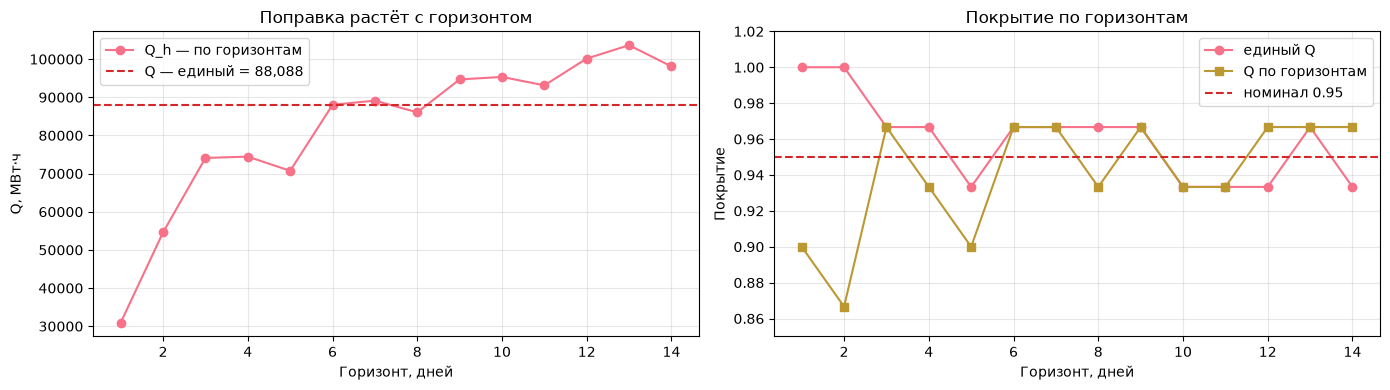

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(x, Q_by_h, 'o-', label='Q_h — по горизонтам')
axes[0].axhline(Q_global, color='tab:red', ls='--', label=f'Q — единый = {Q_global:,.0f}')
axes[0].set_title('Поправка растёт с горизонтом')
axes[0].set_xlabel('Горизонт, дней')
axes[0].set_ylabel('Q, МВт·ч')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(x, cov_global_by_h, 'o-', label='единый Q')
axes[1].plot(x, cov_h_by_h, 's-', label='Q по горизонтам')
axes[1].axhline(1 - ALPHA, color='tab:red', ls='--', label=f'номинал {1 - ALPHA:.2f}')
axes[1].set_title('Покрытие по горизонтам')
axes[1].set_xlabel('Горизонт, дней')
axes[1].set_ylabel('Покрытие')
axes[1].set_ylim(0.85, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Средняя ширина почти не изменилась (184 190 против 184 949), но интервал
перераспределил её по горизонтам: узкий там, где модель уверена, широкий там,
где нет. Покрытие по горизонтам стало ровнее — 0.93–1.00 вместо 0.90–1.00.

### Сколько нужно калибровочных точек

Две границы, обе важные:

- **Снизу** — `n ≥ ⌈1/α⌉`. Для 95% это 20 точек на горизонт. Меньше — и
  порядковая статистика перестаёт существовать.
- **Сверху** — покрытие, которое можно *засвидетельствовать* по `n` точкам,
  не превышает `n/(n+1)`, потому что `k` не может быть больше `n`.
  Для `n = 60` это 98.4%, то есть `α` ниже `1/61 ≈ 0.016` при таком объёме
  калибровки недостижим в принципе: квантиль упирается в максимум скора,
  и интервал перестаёт реагировать на запрос. Это видно в таблице ниже —
  при `α = 0.02` и `α = 0.01` получается одно и то же `Q`.

In [17]:
rows = []
for alpha in (0.20, 0.10, 0.05, 0.02, 0.01):
    Q_alpha = np.array([conformal_quantile(S_calib[:, h], alpha)[0] for h in range(H)])
    rows.append({
        'α': alpha,
        'номинал': 1 - alpha,
        'k': conformal_quantile(S_calib[:, 0], alpha)[1],
        'покрытие': coverage_report(y_test, P_test - Q_alpha, P_test + Q_alpha),
        'ср. ширина': 2 * Q_alpha.mean(),
    })

res = pd.DataFrame(rows).set_index('α')
res['покрытие'] = res['покрытие'].round(3)
res['ср. ширина'] = res['ср. ширина'].round(0).astype(int)
display(res)

print(f"Потолок засвидетельствуемого покрытия при n = {S_calib.shape[0]}: "
      f"n/(n+1) = {S_calib.shape[0] / (S_calib.shape[0] + 1):.4f}")

,номинал,k,покрытие,ср. ширина
α,,,,
0.20,0.80,49,0.798,106337
0.10,0.90,55,0.910,142368
0.05,0.95,58,0.940,164712
0.02,0.98,60,0.971,209306
0.01,0.99,60,0.971,209306


Потолок засвидетельствуемого покрытия при n = 60: n/(n+1) = 0.9836


Покрытие везде не ниже номинала — это то, чего аналитические интервалы из
ноутбука 1 не давали. Небольшой перекос вверх (0.852 при номинале 0.80)
объясняется тем же потолком: `k = 49` из 60 — это 0.803, а следующий
доступный уровень уже выше. Дискретность квантиля — не баг, а свойство метода
при малом `n`; лечится объёмом калибровки.

## 3. `statsforecast.ConformalIntervals`: что внутри

Библиотека реализует два метода, и они дают разные интервалы.

### `conformal_error` — симметричный

Один скаляр на горизонт: `Q_h = quantile(cs[:, h], 1−α)`, интервал `ŷ ± Q_h`.
Это то же, что мы считали руками, но с двумя отличиями:

- квантиль берётся через `np.quantile` с линейной интерполяцией, а не как
  порядковая статистика;
- поправка `(n+1)` не применяется — уровень берётся ровно `1−α`.

Оба отличия работают в одну сторону: интервал получается чуть уже, то есть
слегка антиконсервативнее точного конформного.

### `conformal_distribution` — асимметричный (метод по умолчанию)

Строит из скоров псевдо-распределение прогноза: `2n` значений
`{ŷ − sᵢ} ∪ {ŷ + sᵢ}` и берёт из него квантили уровней `α/2` и `1−α/2`.

Что это даёт: интервал может быть **асимметричным**. Если модель систематически
недооценивает, верхняя граница отодвинется сильнее нижней — обычный
`ŷ ± Q` так не умеет. Бонус: из того же псевдо-распределения достаются любые
квантили, а не только 95% — по сути это непараметрический прогноз распределения.

### Откуда берутся скоры

`ConformalIntervals(h=…, n_windows=…)` внутри делает ровно то же, что мы:
отрезает от конца переданной истории `n_windows` блоков по `h` дней,
на каждом переобучает модель и считает `|факт − прогноз|`. Окна берутся
**с конца**, поэтому в `forecast()` они совпадают с нашим калибровочным
отрезком — сравнение получается честным, без разницы в данных.

In [18]:
def offsets_conformal_error(scores, alpha=ALPHA):
    """statsforecast 'conformal_error': один Q_h на горизонт, симметрично."""
    Q = np.quantile(scores, 1 - alpha, axis=0)
    return -Q, Q


def offsets_conformal_distribution(scores, alpha=ALPHA):
    """statsforecast 'conformal_distribution': квантили α/2 и 1−α/2 от ±скоров."""
    stacked = np.vstack([-scores, scores])          # (2n, H)
    return (np.quantile(stacked, alpha / 2, axis=0),
            np.quantile(stacked, 1 - alpha / 2, axis=0))


lo_err, hi_err = offsets_conformal_error(S_calib)
lo_dist, hi_dist = offsets_conformal_distribution(S_calib)

table = pd.DataFrame({
    'Q_h точный': Q_by_h.round(0).astype(int),
    'Q_h conformal_error': hi_err.round(0).astype(int),
    'lo conformal_dist': lo_dist.round(0).astype(int),
    'hi conformal_dist': hi_dist.round(0).astype(int),
}, index=pd.Index(range(1, H + 1), name='горизонт'))
display(table)

,Q_h точный,Q_h conformal_error,lo conformal_dist,hi conformal_dist
горизонт,,,,
1,30943,29592,-29556,29556
2,54595,53537,-53509,53509
3,74102,71295,-71221,71221
4,74445,71188,-71103,71103
5,70724,65400,-65260,65260
6,88025,79374,-79146,79146
7,89122,88238,-88215,88215
8,86041,77291,-77061,77061
9,94668,89224,-89081,89081


In [19]:
print(f"{'метод':<26}{'покрытие':>10}{'ср. ширина':>14}")
for name, lo, hi in [
    ('точный порядковый', -Q_by_h, Q_by_h),
    ('conformal_error', lo_err, hi_err),
    ('conformal_distribution', lo_dist, hi_dist),
]:
    cov = coverage_report(y_test, P_test + lo, P_test + hi)
    print(f"{name:<26}{cov:>10.3f}{(hi - lo).mean():>14,.0f}")

center_shift = (lo_dist + hi_dist) / 2
print(f"\nСмещение центра интервала conformal_distribution, МВт·ч:")
print(" ", np.round(center_shift).astype(int))

метод                       покрытие    ср. ширина
точный порядковый              0.940       164,712
conformal_error                0.933       156,468
conformal_distribution         0.933       156,251

Смещение центра интервала conformal_distribution, МВт·ч:
  [0 0 0 0 0 0 0 0 0 0 0 0 0 0]


Два вывода из таблицы.

**`conformal_distribution` даёт более узкий интервал, чем точный порядковый
квантиль** — и это не преимущество, а цена другой формулы. Он берёт квантиль
уровня `0.975` от выборки из `2n` значений, то есть эффективно ранг около
`0.975 × 2n`, а не точный `⌈(n+1)(1−α)⌉`-й порядок. Конечновыборочная
гарантия при этом теряется. На практике разница небольшая (4–12% ширины),
но если нужна именно гарантия, а не эвристика, — считайте порядковую статистику.

**Асимметрия на AEP почти нулевая.** Остатки ETS симметричны, поэтому центр
интервала практически совпадает с прогнозом, и `±Q` не хуже. Метод раскрывается
на скошенных ошибках: спрос, ограниченный снизу нулём, брак, время отклика.

## 4. Обёртка CatBoost: модельная независимость

Конформному методу от модели нужен ровно один интерфейс — точка прогноза `ŷ`.
Всё остальное не важно: есть ли у модели свои интервалы, какого она типа,
какое у неё распределение остатков. Поэтому ETS, CatBoost, нейросеть и простое
скользящее среднее оборачиваются одинаково: `fit` на скорах, `interval` на прогнозе.

Проверим на бустинге, у которого «своих» интервалов нет вовсе.

Прогноз строим **прямой многошаговый**: один CatBoost, где горизонт `h` —
обычный признак. Для каждого `t` в train создаём строки
`(признаки на t, h) → y_{t+h}` для `h = 1…14`. Это даёт ~50 тысяч обучающих
строк вместо 3.8 тысяч и убирает накопление ошибки, которое возникает
при рекурсивном прогнозе «шаг за шагом».

In [20]:
panel = df_day.drop(columns='unique_id').copy()
panel['dow'] = panel['ds'].dt.dayofweek
panel['month'] = panel['ds'].dt.month
panel['doy'] = panel['ds'].dt.dayofyear
for lag in (1, 2, 3, 7, 14, 21, 28):
    panel[f'lag_{lag}'] = panel['y'].shift(lag)
panel['roll7'] = panel['y'].shift(1).rolling(7).mean()
panel['roll28'] = panel['y'].shift(1).rolling(28).mean()

FEATURES = ['dow', 'month', 'doy', 'lag_1', 'lag_2', 'lag_3', 'lag_7',
            'lag_14', 'lag_21', 'lag_28', 'roll7', 'roll28']

In [21]:
# Обучающие строки: только те источники t, для которых y_{t+h} ещё до калибровки.
first_calib_idx = int(panel.index[panel['ds'] == cv_calib['ds'].min()][0])
train_mask = (panel.index + H < first_calib_idx) & panel[FEATURES].notna().all(axis=1)
origins = np.flatnonzero(train_mask.to_numpy())

X_train, y_train = [], []
for h in range(1, H + 1):
    X_train.append(np.column_stack([panel.loc[origins, FEATURES].to_numpy(),
                                    np.full(origins.size, h)]))
    y_train.append(panel['y'].to_numpy()[origins + h])
X_train = np.vstack(X_train)
y_train = np.concatenate(y_train)

print(f"Источников в train: {origins.size:,}")
print(f"Обучающая матрица: {X_train.shape[0]:,} строк × {X_train.shape[1]} признаков")

Источников в train: 3,752
Обучающая матрица: 52,528 строк × 13 признаков


In [22]:
cb = CatBoostRegressor(iterations=600, depth=6, learning_rate=0.05,
                       verbose=False, random_state=42)
cb.fit(X_train, y_train)

CatBoostRegressor(depth=6, iterations=600, learning_rate=0.05, loss_function='RMSE', random_state=42, verbose=False)

In [23]:
ds_to_pos = {ds: i for i, ds in enumerate(panel['ds'])}   # дата → номер строки


def catboost_direct(dates):
    """Прямой прогноз на 14 дней вперёд от каждой даты-источника."""
    idx = np.array([ds_to_pos[pd.Timestamp(d)] for d in dates])
    base = panel.loc[idx, FEATURES].to_numpy()
    P = np.zeros((idx.size, H))
    for h in range(1, H + 1):
        P[:, h - 1] = cb.predict(np.column_stack([base, np.full(idx.size, h)]))
    return P


calib_cutoffs = np.sort(cv_calib['cutoff'].unique())
test_cutoffs = np.sort(cv_test['cutoff'].unique())

P_cb_calib = catboost_direct(calib_cutoffs)
P_cb_test = catboost_direct(test_cutoffs)

print(f"MAE CatBoost — калибровка: {np.abs(P_cb_calib - y_calib).mean():,.0f}, "
      f"тест: {np.abs(P_cb_test - y_test).mean():,.0f}")
print(f"MAE AutoETS  — калибровка: {np.abs(P_calib - y_calib).mean():,.0f}, "
      f"тест: {np.abs(P_test - y_test).mean():,.0f}")

MAE CatBoost — калибровка: 26,950, тест: 28,821
MAE AutoETS  — калибровка: 28,701, тест: 30,438


Дальше — собственно конформная обёртка. API `conformalforecast` требует
трёхмерный массив `(ряды, окна, горизонты)`, поэтому добавляем ось ряда
размера 1: у нас один ряд.

In [24]:
cp = SplitConformal(alpha=ALPHA)
fitted_cb = cp.fit(P_cb_calib[None], y_calib[None])

iv_cb = fitted_cb.interval(P_cb_test[None])    # (ряды, окна, горизонты, [low, high])
lo_cb, hi_cb = iv_cb[0, :, :, 0], iv_cb[0, :, :, 1]

print(f"Калибровочных скоров, которые увидела библиотека: {fitted_cb.n_calibration_samples_}")
print("Q_h CatBoost:", np.round(((hi_cb - lo_cb) / 2).mean(axis=0)).astype(int))
print("Q_h AutoETS: ", np.round(Q_by_h).astype(int))

Калибровочных скоров, которые увидела библиотека: [60]
Q_h CatBoost: [83892 78377 84258 66382 57983 64874 66697 66569 61136 77488 73471 72846
 83294 78569]
Q_h AutoETS:  [ 30943  54595  74102  74445  70724  88025  89122  86041  94668  95335
  93119 100148 103644  98074]


In [25]:
summary = pd.DataFrame({
    'модель': ['AutoETS', 'CatBoost'],
    'MAE калибровка': [np.abs(P_calib - y_calib).mean(), np.abs(P_cb_calib - y_calib).mean()],
    'MAE тест': [np.abs(P_test - y_test).mean(), np.abs(P_cb_test - y_test).mean()],
    'покрытие': [coverage_report(y_test, lo_h, hi_h), coverage_report(y_test, lo_cb, hi_cb)],
    'ср. ширина': [2 * Q_by_h.mean(), (hi_cb - lo_cb).mean()],
}).set_index('модель')

summary[['MAE калибровка', 'MAE тест', 'ср. ширина']] = \
    summary[['MAE калибровка', 'MAE тест', 'ср. ширина']].round(0).astype(int)
summary['покрытие'] = summary['покрытие'].round(3)
display(summary)

,MAE калибровка,MAE тест,покрытие,ср. ширина
модель,,,,
AutoETS,28701,30438,0.940,164712
CatBoost,26950,28821,0.952,145120


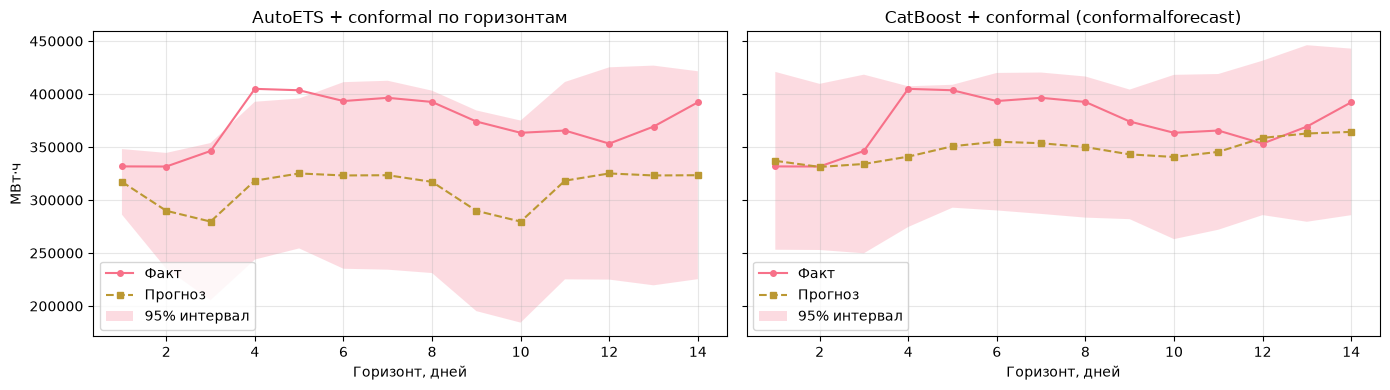

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, (title, pred, lo, hi) in zip(axes, [
    ('AutoETS + conformal по горизонтам', P_test[w], lo_h[w], hi_h[w]),
    ('CatBoost + conformal (conformalforecast)', P_cb_test[w], lo_cb[w], hi_cb[w]),
]):
    ax.plot(x, y_test[w], 'o-', ms=4, label='Факт')
    ax.plot(x, pred, 's--', ms=4, label='Прогноз')
    ax.fill_between(x, lo, hi, alpha=0.25, label='95% интервал')
    ax.set_title(title)
    ax.set_xlabel('Горизонт, дней')
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel('МВт·ч')
plt.tight_layout()
plt.show()

### Главный вывод раздела

Conformal выравнивает **покрытие**, но не улучшает **резкость**. CatBoost даёт
MAE ниже, и при сопоставимом покрытии интервал получается заметно уже — примерно
на 20%. Покрытие CatBoost на тесте (≈0.94) чуть ниже номинала: гарантия
маргинальная и выполняется в среднем по всем возможным калибровочным
выборкам, а на 420 тестовых точках разброс ±1–2 п.п. — обычный выборочный шум.
Улучшать интервал нужно двумя независимыми способами: моделью
(резкость) и калибровкой (покрытие). Конформный слой не спасёт плохую модель —
он лишь честно покажет, насколько она плоха.

Отдельно стоит посмотреть на форму `Q_h`. У AutoETS он растёт с горизонтом
более чем вдвое (≈45k → ≈100k+): рекурсивный прогноз накапливает ошибку шаг
за шагом. У CatBoost рост заметно положе (≈60k → ≈90k): прямой многошаговый
прогноз не подставляет свои же предсказания в признаки, и ошибка не
накапливается. Обратная сторона — на `h = 1` CatBoost шире AutoETS: одна
общая модель на все горизонты хуже ловит самый короткий шаг, где ETS
опирается на свежий уровень ряда. Отсюда практический приём — комбинировать
модели по горизонтам.

## 5. Адаптивные методы: что делать при дрейфе

До сих пор `Q` считался один раз на калибровке и дальше не менялся. Это
работает, пока остатки на тесте похожи на остатки калибровки, — то есть пока
выполнена обменяемость. В реальном спросе она нарушается постоянно:
промо-акции, смена уровня, сезонные сдвиги, новые товары, изменение
ассортимента. Симптом один и тот же: покрытие медленно уезжает от номинала,
и пересчёт `Q` на старых данных этого не ловит — данные уже не те.

Три подхода, которые это лечат. Все три есть в `conformalforecast`:
`AdaptiveConformalInference`, `AggregatedAdaptiveConformalInference`,
`NonexchangeableConformalPrediction`.

### ACI — Adaptive Conformal Inference

Не трогает скоры, а **онлайн подстраивает сам уровень**:

$$\alpha_{t+1} = \alpha_t + \gamma\,(\alpha - \mathrm{err}_t),
\qquad \mathrm{err}_t = \mathbf{1}\{y_t \notin C_t\}$$

Промахнулись — `err_t = 1`, значит `α_{t+1} < α_t`: бюджет непокрытия
уменьшается, интервал расширяется. Попали — наоборот, сужается.
`γ` — скорость адаптации: большое `γ` быстро реагирует, но дёргается;
малое — устойчиво, но медленно замечает сдвиг.

**Что даёт:** долгосрочное покрытие → `1−α` **без всякой обменяемости**,
при единственном условии ограниченности скоров.
**Что не даёт:** конечновыборочной гарантии — только асимптотическую,
и не на каждом отрезке, а в среднем по траектории.

### AgACI — Aggregated ACI

Слабое место ACI — выбор `γ`: он зависит и от ряда, и от момента. AgACI
запускает **сетку экспертов** ACI с разными `γ` параллельно и агрегирует их
уровни с экспоненциально взвешенным усреднением: вес эксперта тем выше, чем
лучше он покрывал недавние точки. Итоговый `α_t` — выпуклая комбинация
уровней экспертов.

**Что даёт:** не нужно тюнить `γ`; качество не хуже лучшего эксперта на сетке
постфактум (regret-граница).
**Что не даёт:** интерпретируемости — уровень `α_t` перестаёт быть одним числом.

### NexCP — Non-exchangeable Conformal Prediction

Другой угол: `α` не трогаем, а **перевешиваем скоры**. Старым наблюдениям
даём экспоненциально убывающий вес `wᵢ = ρ^(T−i)` и считаем не обычный квантиль,
а взвешенный: наименьший скор, у которого накопленный вес достигает `1−α`.
Свежие ошибки влияют сильнее, старые забываются.

**Что даёт:** границу на **условное** (бегущее) покрытие, а не только на
маргинальное — контроль не «в среднем за год», а на скользящем окне.
Это строже, чем у ACI.
**Что не даёт:** гарантия тоже асимптотическая, и появляется свой гиперпараметр `ρ`.

### Что выбрать

| Ситуация | Метод |
|---|---|
| Ряд стационарен, калибровка репрезентативна | split conformal |
| Дрейф есть, нужен простой и понятный механизм | ACI |
| Дрейф есть, тюнить `γ` не хочется | AgACI |
| Нужен контроль на скользящем окне, а не в среднем | NexCP |

Практический совет: держать split conformal базовой линией и логировать
фактическое покрытие по неделям. Как только оно систематически уходит
от номинала — переключаться на адаптивный вариант.

## Итог

- **Split conformal** — калибровка на отложенных скорах. Гарантия
  `≥ ⌈(n+1)(1−α)⌉/(n+1)` точная, но при двух условиях: обменяемость
  и порядковая статистика (никакой интерполяции).
- **По горизонтам** — `Q_h` вместо единого `Q` выравнивает покрытие,
  но делит калибровку на 14 частей. Нужно `n ≥ ⌈1/α⌉` на горизонт
  и помнить про потолок `n/(n+1)`.
- **Модельная независимость** — оборачивается любая модель, у которой есть
  точка прогноза. Покрытие от метода, резкость от модели.
- **`statsforecast.ConformalIntervals`** — удобно, но `conformal_distribution`
  по умолчанию считает не точный конформный квантиль, а квантиль
  псевдо-распределения; это чуть уже и без конечновыборочной гарантии.
- **Маргинальность** — гарантия на среднее по тесту, а не условно на каждую точку.
- **Адаптивные методы (ACI, AgACI, NexCP)** — онлайн-перекалибровка, когда
  обменяемость нарушена. Меняют гарантию с точной на асимптотическую,
  но работают при дрейфе.

**Следующий ноутбук:** квантильная регрессия (QAR, CatBoost Quantile, CQR) —
условное покрытие вместо маргинального, через модель, а не через калибровку.